# Results: registration-free spherical representation for CN vs. Dementia

This notebook presents the final results and exports the **paper-ready figures and tables**.
It reads only the outputs of `train.py` (`runs/`) and `evaluate.py` (`results/`), plus the
local `spherical_cache/` for Figure 1. Every number in the text below is computed from those
files, so re-running the notebook after new runs keeps the text and figures in sync.

**Exports** (`figures/`):

| Format | Use |
|---|---|
| `*.pdf` | vector, for the manuscript (fonts embedded) |
| `*.tif` | 600 dpi, LZW, for journal upload systems |
| `*.png` | 600 dpi, for slides and previews |
| `table*.tex` | booktabs LaTeX tables |
| `captions.md` | draft figure captions with the numbers filled in |

Figures follow Elsevier artwork guidelines (CMIG): widths of 90 mm (single column),
140 mm (1.5 columns) or 190 mm (double column); Arial; 7 pt text; panel labels (a), (b).

**Pre-declared analysis:** best-epoch weights are the primary result for the deep networks
(top-K weight averaging is an ablation); every decision threshold was chosen on the
validation partition (Youden's J); confidence intervals are 95% percentile bootstrap
(2,000 paired test-set resamples); pairwise p-values are Holm-adjusted.

In [1]:
import os, json, glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO        = Path(os.environ.get("ADNI_REPO", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
RESULTS_DIR = Path(os.environ.get("ADNI_RESULTS", REPO / "results"))
RUNS_DIR    = Path(os.environ.get("ADNI_RUNS", REPO / "runs"))
CACHE_DIR   = Path(os.environ.get("ADNI_CACHE", REPO / "spherical_cache"))
FIG_DIR     = Path(os.environ.get("ADNI_FIGURES", REPO / "figures"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── journal geometry and typography (Elsevier artwork guidelines) ─────────
MM = 1 / 25.4
COL1, COL15, COL2 = 90 * MM, 140 * MM, 190 * MM
INK, INK_2, GRID = "#1a1a1a", "#555555", "#e2e2e2"
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "xtick.labelsize": 9,
    "ytick.labelsize": 9, "legend.fontsize": 9, "legend.title_fontsize": 9,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.4,
    "lines.linewidth": 1.2, "lines.markersize": 4, "legend.frameon": False,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Fixed colour per model family, assigned once and never re-cycled. The
# spacing control is neutral grey. Weight variant is shown by line style,
# so identity never depends on colour alone.
FAMILY_COLOR = {
    "CNN3D": "#2a78d6", "Spherical Transformer": "#eb6834", "SVM (RBF)": "#1baf7a",
    "XGBoost": "#c98500", "Cosine Similarity": "#d55181",
    "Voxel spacing only (control)": "#8a8984",
    # registration-based reference: coloured by registration type
    "MNI SyN": "#008300", "MNI affine": "#4a3aa7", "Regional volumes": "#e34948",
}
PRIMARY = ["CNN3D (best epoch)", "Spherical Transformer (best epoch)",
           "SVM (RBF)", "XGBoost", "Cosine Similarity"]
CONTROL = "Voxel spacing only (control)"
ROI = "Regional volumes (MNI SyN atlas)"
REGISTERED = ["CNN3D, MNI SyN (best epoch)", "CNN3D, MNI affine (best epoch)",
              "SVM (RBF), MNI SyN", "SVM (RBF), MNI affine",
              "XGBoost, MNI SyN", "XGBoost, MNI affine",
              "Cosine Similarity, MNI SyN", "Cosine Similarity, MNI affine", ROI]
ORDER = ["CNN3D (best epoch)", "CNN3D (top-K avg)",
         "Spherical Transformer (best epoch)", "Spherical Transformer (top-K avg)",
         "SVM (RBF)", "XGBoost", "Cosine Similarity"] + REGISTERED + [CONTROL]
SHORT = {"CNN3D (best epoch)": "CNN3D", "Spherical Transformer (best epoch)": "Sph. Transformer",
         "CNN3D (top-K avg)": "CNN3D (top-5 avg)",
         "Spherical Transformer (top-K avg)": "Sph. Transformer (top-5 avg)",
         "SVM (RBF)": "SVM (RBF)", "XGBoost": "XGBoost", "Cosine Similarity": "Cosine similarity",
         "CNN3D, MNI SyN (best epoch)": "CNN3D · MNI SyN", "CNN3D, MNI affine (best epoch)": "CNN3D · MNI affine",
         "SVM (RBF), MNI SyN": "SVM · MNI SyN", "SVM (RBF), MNI affine": "SVM · MNI affine",
         "XGBoost, MNI SyN": "XGBoost · MNI SyN", "XGBoost, MNI affine": "XGBoost · MNI affine",
         "Cosine Similarity, MNI SyN": "Cosine · MNI SyN", "Cosine Similarity, MNI affine": "Cosine · MNI affine",
         ROI: "Regional volumes (atlas)", CONTROL: "Voxel spacing only"}
PROTO = {"iso1.0": "≤1.0 mm voxels", "slice1.2": "1.2 mm slices"}

def family(c):
    if c == ROI:
        return "Regional volumes"
    if "MNI SyN" in c:
        return "MNI SyN"
    if "MNI affine" in c:
        return "MNI affine"
    return c.split(" (")[0] if c.startswith(("CNN3D", "Spherical")) else c

def color(c):
    return FAMILY_COLOR[family(c)]

def lstyle(c):
    return (0, (3, 1.5)) if "top-K" in c else "-"

def panel(ax, letter, x=-0.02, y=1.02):
    ax.text(x, y, f"({letter})", transform=ax.transAxes, fontsize=10, fontweight="bold",
            ha="right", va="bottom")

CAPTIONS = {}

def save(fig, name, caption):
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=600)
    fig.savefig(FIG_DIR / f"{name}.tif", dpi=600, pil_kwargs={"compression": "tiff_lzw"})
    CAPTIONS[name] = caption
    w, h = fig.get_size_inches() / MM
    display(Markdown(f"**{name}** ({w:.0f} × {h:.0f} mm): {caption}"))

def ci(r, k="AUC", d=3):
    return f"{r[f'{k}_mean']:.{d}f} (95% CI {r[f'{k}_lo']:.{d}f}–{r[f'{k}_hi']:.{d}f})"

def pfmt(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

print("results:", RESULTS_DIR, "| runs:", RUNS_DIR, "| figures ->", FIG_DIR)

results: F:\adni-spherical-classification\results | runs: F:\adni-spherical-classification\runs | figures -> F:\adni-spherical-classification\figures


In [2]:
summary  = pd.read_csv(RESULTS_DIR / "summary.csv").set_index("config")
per_seed = pd.read_csv(RESULTS_DIR / "metrics_per_seed.csv")
pairwise = pd.read_csv(RESULTS_DIR / "pairwise_auc.csv")
subgroup = pd.read_csv(RESULTS_DIR / "subgroup_auc.csv")
preds    = pd.read_csv(RESULTS_DIR / "predictions.csv")
meta     = json.loads((RESULTS_DIR / "summary.json").read_text())
cross    = pd.read_csv(RESULTS_DIR / "cross_protocol.csv") if (RESULTS_DIR / "cross_protocol.csv").exists() else None
manifest = pd.read_csv(REPO / "cohort" / "manifest.csv")

present = [c for c in ORDER if c in summary.index]
primary = [c for c in PRIMARY if c in summary.index]
deep_cross = cross is not None and cross["config"].str.startswith(("CNN3D", "Spherical")).any()

status = pd.DataFrame({"seeds": summary.loc[present, "n_seeds"].astype(int)})
display(Markdown("### Inputs found"))
display(status.T)
display(Markdown(
    f"Test partition: **{meta['n_test']} subjects ({meta['n_test_dementia']} Dementia)**; "
    f"PCA (50 components) explained {meta['pca_variance_explained']:.1%} of training variance. "
    + ("Cross-protocol results include the deep networks." if deep_cross else
       "Cross-protocol results cover **the classical models only**; the deep networks' "
       "protocol-restricted runs (`run_experiments.ps1 -CrossProtocol`) have not been trained yet.")))

### Inputs found

config,CNN3D (best epoch),CNN3D (top-K avg),Spherical Transformer (best epoch),Spherical Transformer (top-K avg),SVM (RBF),XGBoost,Cosine Similarity,"CNN3D, MNI SyN (best epoch)","CNN3D, MNI affine (best epoch)","SVM (RBF), MNI SyN","SVM (RBF), MNI affine","XGBoost, MNI SyN","XGBoost, MNI affine","Cosine Similarity, MNI SyN","Cosine Similarity, MNI affine",Regional volumes (MNI SyN atlas),Voxel spacing only (control)
seeds,5,5,5,5,1,5,1,5,5,1,1,5,5,1,1,1,1


Test partition: **254 subjects (70 Dementia)**; PCA (50 components) explained 49.8% of training variance. Cross-protocol results include the deep networks.

## 1. Cohort

In [3]:
t1 = (manifest.assign(Protocol=manifest["protocol"].map(PROTO))
      .pivot_table(index="split", columns=["Diagnosis", "Protocol"], values="PTID", aggfunc="count", fill_value=0)
      .reindex(["train", "validation", "test"]))
t1.index = ["Training", "Validation", "Test"]
t1["Total"] = t1.sum(axis=1)
t1.loc["Total"] = t1.sum()
display(t1)
(FIG_DIR / "table1_cohort.tex").write_text(
    t1.to_latex(multicolumn=True, multicolumn_format="c", escape=True), encoding="utf-8")

rate = manifest.assign(d=manifest["Diagnosis"].eq("Dementia")).groupby("protocol")["d"].agg(["mean", "size"])
display(Markdown(
    f"**{len(manifest):,} subjects.** Acquisition protocol is associated with diagnosis: "
    f"{rate.loc['slice1.2','mean']:.0%} of the {rate.loc['slice1.2','size']} scans with 1.2 mm slices "
    f"are Dementia, versus {rate.loc['iso1.0','mean']:.0%} of the {rate.loc['iso1.0','size']} scans "
    f"with ≤1.0 mm voxels. Sections 5–6 test whether the classifiers exploit this."))

Diagnosis             CN                     Dementia                Total
Protocol   1.2 mm slices ≤1.0 mm voxels 1.2 mm slices ≤1.0 mm voxels      
Training             359            496           236             92  1183
Validation            83            100            50             21   254
Test                  79            105            58             12   254
Total                521            701           344            125  1691

**1,691 subjects.** Acquisition protocol is associated with diagnosis: 40% of the 865 scans with 1.2 mm slices are Dementia, versus 15% of the 826 scans with ≤1.0 mm voxels. Sections 5–6 test whether the classifiers exploit this.

## 2. Main result: test-set discrimination

In [4]:
METRICS = ["AUC", "Sens", "Spec", "PPV", "NPV", "F1", "Acc"]
NAMES = {"AUC": "AUC", "Sens": "Sensitivity", "Spec": "Specificity", "PPV": "PPV", "NPV": "NPV",
         "F1": "F1 score", "Acc": "Accuracy"}

def cell(r, k, latex=False):
    pm = r"$\pm$" if latex else "±"
    sd = f" {pm} {r[f'{k}_sd']:.3f}" if r["n_seeds"] > 1 else ""
    dash = "--" if latex else "–"
    return f"{r[f'{k}_mean']:.3f}{sd} ({r[f'{k}_lo']:.3f}{dash}{r[f'{k}_hi']:.3f})"

def results_table(configs, latex=False):
    t = pd.DataFrame({NAMES[k]: [cell(summary.loc[c], k, latex) for c in configs] for k in METRICS},
                     index=[SHORT[c] for c in configs])
    t.insert(0, "Seeds", summary.loc[configs, "n_seeds"].astype(int).values)
    t.index.name = "Model"
    return t

t2 = results_table(present)
display(t2)
(FIG_DIR / "table2_results.tex").write_text(results_table(present, latex=True).to_latex(escape=False), encoding="utf-8")
t2.to_csv(FIG_DIR / "table2_results.csv")

best = summary.loc[primary, "AUC_mean"].idxmax()
deep = [c for c in primary if c.startswith(("CNN3D", "Spherical"))]
classical = [c for c in primary if c not in deep]
display(Markdown(
    "Values are mean ± SD across seeds with the 95% bootstrap CI of the seed-mean in parentheses; "
    "threshold metrics use each model's validation-chosen threshold.\n\n"
    f"- **Highest AUC: {SHORT[best]}, {ci(summary.loc[best])}.**\n"
    + "".join(f"- {SHORT[c]}: AUC {ci(summary.loc[c])}\n" for c in primary if c != best)
    + (f"- The voxel-spacing-only control reaches AUC {ci(summary.loc[CONTROL])}: "
       "the protocol association alone is far from negligible, which motivates Sections 5–6.\n"
       if CONTROL in summary.index else "")))

,Seeds,AUC,Sensitivity,Specificity,PPV,NPV,F1 score,Accuracy
Model,,,,,,,,
CNN3D,5,0.893 ± 0.007 (0.845–0.934),0.766 ± 0.105 (0.687–0.842),0.870 ± 0.039 (0.824–0.911),0.696 ± 0.045 (0.605–0.790),0.909 ± 0.035 (0.870–0.943),0.724 ± 0.037 (0.651–0.793),0.841 ± 0.014 (0.802–0.879)
CNN3D (top-5 avg),5,0.896 ± 0.006 (0.848–0.937),0.849 ± 0.051 (0.775–0.918),0.840 ± 0.027 (0.787–0.888),0.671 ± 0.029 (0.580–0.764),0.937 ± 0.018 (0.901–0.968),0.748 ± 0.009 (0.674–0.813),0.843 ± 0.008 (0.800–0.883)
Sph. Transformer,5,0.882 ± 0.012 (0.835–0.926),0.800 ± 0.058 (0.718–0.875),0.813 ± 0.028 (0.762–0.859),0.620 ± 0.035 (0.531–0.710),0.915 ± 0.022 (0.875–0.949),0.698 ± 0.037 (0.623–0.768),0.809 ± 0.024 (0.769–0.848)
Sph. Transformer (top-5 avg),5,0.883 ± 0.012 (0.835–0.927),0.840 ± 0.038 (0.762–0.910),0.774 ± 0.068 (0.722–0.823),0.592 ± 0.065 (0.506–0.680),0.927 ± 0.015 (0.887–0.959),0.693 ± 0.046 (0.616–0.762),0.792 ± 0.047 (0.752–0.832)
SVM (RBF),1,0.860 (0.806–0.908),0.814 (0.719–0.901),0.766 (0.705–0.826),0.570 (0.471–0.670),0.916 (0.869–0.957),0.671 (0.583–0.747),0.780 (0.728–0.831)
XGBoost,5,0.847 ± 0.007 (0.799–0.894),0.834 ± 0.071 (0.761–0.902),0.715 ± 0.051 (0.658–0.773),0.530 ± 0.030 (0.440–0.619),0.921 ± 0.026 (0.880–0.956),0.646 ± 0.019 (0.570–0.716),0.748 ± 0.022 (0.703–0.795)
Cosine similarity,1,0.801 (0.745–0.857),0.900 (0.826–0.966),0.609 (0.537–0.679),0.467 (0.384–0.557),0.941 (0.896–0.982),0.615 (0.534–0.696),0.689 (0.634–0.748)
CNN3D · MNI SyN,5,0.893 ± 0.002 (0.854–0.930),0.817 ± 0.056 (0.741–0.895),0.804 ± 0.048 (0.751–0.855),0.618 ± 0.040 (0.525–0.710),0.922 ± 0.019 (0.881–0.956),0.701 ± 0.012 (0.627–0.772),0.808 ± 0.020 (0.765–0.850)
CNN3D · MNI affine,5,0.882 ± 0.002 (0.842–0.920),0.826 ± 0.052 (0.746–0.902),0.767 ± 0.071 (0.712–0.820),0.582 ± 0.059 (0.492–0.675),0.922 ± 0.016 (0.880–0.958),0.679 ± 0.024 (0.604–0.751),0.783 ± 0.037 (0.738–0.826)


Values are mean ± SD across seeds with the 95% bootstrap CI of the seed-mean in parentheses; threshold metrics use each model's validation-chosen threshold.

- **Highest AUC: CNN3D, 0.893 (95% CI 0.845–0.934).**
- Sph. Transformer: AUC 0.882 (95% CI 0.835–0.926)
- SVM (RBF): AUC 0.860 (95% CI 0.806–0.908)
- XGBoost: AUC 0.847 (95% CI 0.799–0.894)
- Cosine similarity: AUC 0.801 (95% CI 0.745–0.857)
- The voxel-spacing-only control reaches AUC 0.702 (95% CI 0.633–0.763): the protocol association alone is far from negligible, which motivates Sections 5–6.


**fig2_roc** (90 × 115 mm): Receiver operating characteristic curves on the held-out test partition (n = 254, 70 Dementia). For the deep networks and XGBoost, the curve is the vertical average over five training seeds and the shaded band is ±1 SD; dots mark the mean operating point at each model's validation-chosen (Youden) threshold. Legend values are mean test AUC.

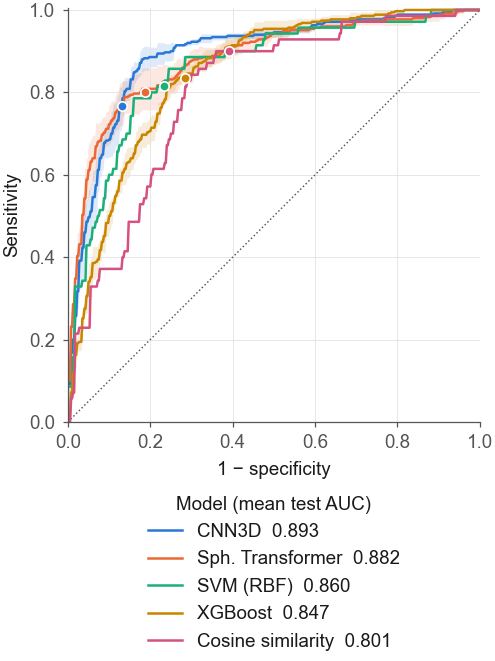

In [5]:
grid = np.linspace(0, 1, 401)

def roc_points(y, s):
    order = np.argsort(-s, kind="mergesort")
    y, s = y[order], s[order]
    distinct = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    tps = np.cumsum(y)[distinct]
    fps = (distinct + 1) - tps
    return np.r_[0, fps / fps[-1]], np.r_[0, tps / tps[-1]]

test = preds[preds["split"] == "test"]
fig, ax = plt.subplots(figsize=(COL1, COL1 * 1.28))
ax.plot([0, 1], [0, 1], ls=":", lw=0.7, color=INK_2)
for c in primary:
    curves, ops = [], []
    for _, g in test[test["config"] == c].groupby("seed", dropna=False):
        y, s = g["label"].to_numpy(), g["score"].to_numpy()
        fpr, tpr = roc_points(y, s)
        curves.append(np.interp(grid, fpr, tpr))
        pred = s >= g["threshold"].iloc[0]
        ops.append((pred[y == 0].mean(), pred[y == 1].mean()))
    curves = np.array(curves)
    mean = curves.mean(0)
    r = summary.loc[c]
    ax.plot(grid, mean, color=color(c), lw=1.2, label=f"{SHORT[c]}  {r['AUC_mean']:.3f}")
    if len(curves) > 1:
        sd = curves.std(0)
        ax.fill_between(grid, np.clip(mean - sd, 0, 1), np.clip(mean + sd, 0, 1), color=color(c), alpha=0.15, lw=0)
    ax.plot(*np.mean(ops, axis=0), "o", ms=4.5, color=color(c), mec="white", mew=0.8, zorder=5)
ax.set(xlabel="1 − specificity", ylabel="Sensitivity", xlim=(0, 1), ylim=(0, 1.005), aspect="equal")
ax.set_xticks([0, .2, .4, .6, .8, 1]); ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, title="Model (mean test AUC)",
          handlelength=1.8, borderaxespad=0)
save(fig, "fig2_roc",
     f"Receiver operating characteristic curves on the held-out test partition (n = {meta['n_test']}, "
     f"{meta['n_test_dementia']} Dementia). For the deep networks and XGBoost, the curve is the vertical "
     "average over five training seeds and the shaded band is ±1 SD; dots mark the mean operating point "
     "at each model's validation-chosen (Youden) threshold. Legend values are mean test AUC.")
plt.show()

**fig3_auc_forest** (140 × 115 mm): Test AUC of every configuration. Large dots: mean across seeds; bars: 95% bootstrap CI of the seed-mean (2,000 paired resamples); small dots: individual seeds; dashed bars: top-5 checkpoint averaging (ablation). The voxel-spacing-only classifier is a protocol reference, not a competitor.

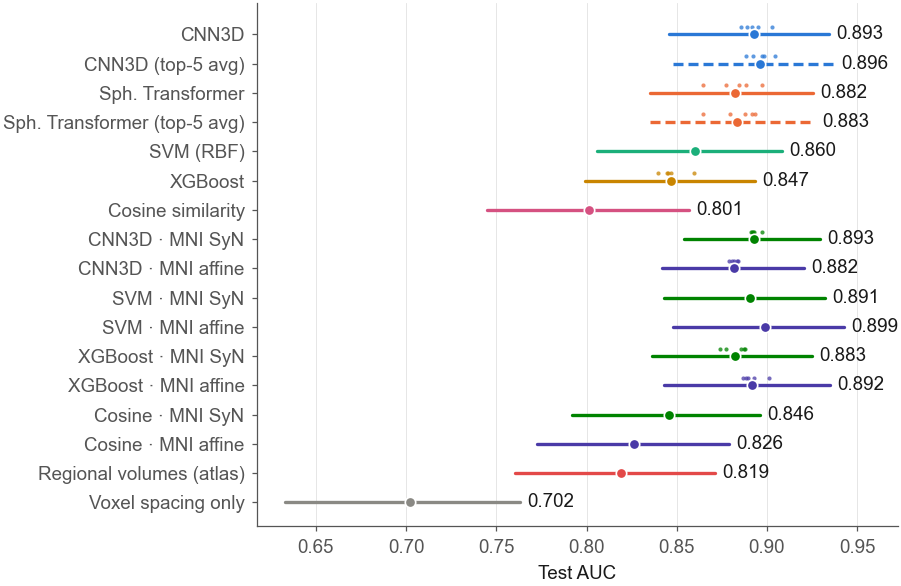

In [6]:
fig, ax = plt.subplots(figsize=(COL15, 0.24 * len(present) + 0.45))
ys = np.arange(len(present))[::-1]
for y, c in zip(ys, present):
    r = summary.loc[c]
    ax.plot([r["AUC_lo"], r["AUC_hi"]], [y, y], color=color(c), lw=1.6, ls=lstyle(c), solid_capstyle="round")
    seeds = per_seed.loc[per_seed["config"] == c, "AUC"]
    if len(seeds) > 1:
        ax.plot(seeds, np.full(len(seeds), y + 0.26), "o", ms=2, color=color(c), alpha=0.75, mew=0)
    ax.plot(r["AUC_mean"], y, "o", ms=5, color=color(c), mec="white", mew=0.8, zorder=5)
    ax.text(r["AUC_hi"] + 0.004, y, f"{r['AUC_mean']:.3f}", va="center", fontsize=9)
ax.set_yticks(ys, [SHORT[c] for c in present])
ax.set_xlabel("Test AUC")
ax.grid(axis="y", visible=False)
ax.set_xlim(right=max(summary.loc[present, "AUC_hi"]) + 0.03)
save(fig, "fig3_auc_forest",
     "Test AUC of every configuration. Large dots: mean across seeds; bars: 95% bootstrap CI of the "
     "seed-mean (2,000 paired resamples); small dots: individual seeds; dashed bars: top-5 checkpoint "
     "averaging (ablation). The voxel-spacing-only classifier is a protocol reference, not a competitor.")
plt.show()

## 3. Statistical comparison between models

In [7]:
pw = pairwise[pairwise["config_a"].isin(primary) & pairwise["config_b"].isin(primary)].copy()
flip = pw["delta_AUC"] < 0                        # orient: better model first
pw.loc[flip, ["config_a", "config_b"]] = pw.loc[flip, ["config_b", "config_a"]].values
pw.loc[flip, "delta_AUC"] *= -1
pw.loc[flip, ["lo", "hi"]] = -pw.loc[flip, ["hi", "lo"]].values
pw = pw.sort_values("delta_AUC", ascending=False).reset_index(drop=True)

t3 = pd.DataFrame({
    "Comparison": [f"{SHORT[a]} vs {SHORT[b]}" for a, b in zip(pw["config_a"], pw["config_b"])],
    "ΔAUC": pw["delta_AUC"].map("{:.3f}".format),
    "95% CI": [f"{l:.3f} to {h:.3f}" for l, h in zip(pw["lo"], pw["hi"])],
    "p (unadjusted)": pw["p_boot"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"),
    "p (Holm)": pw["p_holm"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"),
})
display(t3)
t3l = t3.copy()
t3l["95% CI"] = [f"{l:.3f} to {h:.3f}" for l, h in zip(pw["lo"], pw["hi"])]
(FIG_DIR / "table3_pairwise.tex").write_text(
    t3l.rename(columns={"ΔAUC": r"$\Delta$AUC", "95% CI": r"95\% CI"})
       .to_latex(index=False, escape=False).replace("<0.001", "$<$0.001"),
    encoding="utf-8")

sig = pw[pw["p_holm"] < 0.05]
nominal = pw[(pw["p_boot"] < 0.05) & (pw["p_holm"] >= 0.05)]
display(Markdown(
    f"Paired bootstrap on the difference in seed-mean AUC, Holm-adjusted over all "
    f"{len(pairwise)} pairs of configurations.\n\n"
    + ("**Significant after adjustment:** " + "; ".join(
        f"{SHORT[a]} > {SHORT[b]} (ΔAUC {d:.3f}, {pfmt(p)})"
        for a, b, d, p in zip(sig["config_a"], sig["config_b"], sig["delta_AUC"], sig["p_holm"])) + ".\n\n"
       if len(sig) else "**No pairwise difference is significant after adjustment.**\n\n")
    + ("Nominally significant but **not** after adjustment (do not claim): " + "; ".join(
        f"{SHORT[a]} vs {SHORT[b]} (ΔAUC {d:.3f}, unadjusted {pfmt(p)})"
        for a, b, d, p in zip(nominal["config_a"], nominal["config_b"], nominal["delta_AUC"], nominal["p_boot"])) + "."
       if len(nominal) else "")))

,Comparison,ΔAUC,95% CI,p (unadjusted),p (Holm)
0,CNN3D vs Cosine similarity,0.092,0.040 to 0.141,<0.001,0.011
1,Sph. Transformer vs Cosine similarity,0.081,0.034 to 0.128,<0.001,0.011
2,SVM (RBF) vs Cosine similarity,0.059,0.010 to 0.106,0.017,0.289
3,XGBoost vs Cosine similarity,0.046,0.006 to 0.089,0.028,0.392
4,CNN3D vs XGBoost,0.046,0.005 to 0.085,0.028,0.392
5,Sph. Transformer vs XGBoost,0.035,-0.003 to 0.072,0.070,0.700
6,CNN3D vs SVM (RBF),0.032,-0.000 to 0.066,0.051,0.612
7,Sph. Transformer vs SVM (RBF),0.022,-0.003 to 0.047,0.076,0.700
8,SVM (RBF) vs XGBoost,0.013,-0.021 to 0.045,0.425,1.000
9,CNN3D vs Sph. Transformer,0.010,-0.023 to 0.046,0.582,1.000


Paired bootstrap on the difference in seed-mean AUC, Holm-adjusted over all 21 pairs of configurations.

**Significant after adjustment:** CNN3D > Cosine similarity (ΔAUC 0.092, p = 0.011); Sph. Transformer > Cosine similarity (ΔAUC 0.081, p = 0.011).

Nominally significant but **not** after adjustment (do not claim): SVM (RBF) vs Cosine similarity (ΔAUC 0.059, unadjusted p = 0.017); XGBoost vs Cosine similarity (ΔAUC 0.046, unadjusted p = 0.028); CNN3D vs XGBoost (ΔAUC 0.046, unadjusted p = 0.028).

**fig4_pairwise** (140 × 69 mm): Pairwise differences in seed-mean test AUC between the primary configurations. Bars: unadjusted 95% paired-bootstrap CI; dots coloured by the better model; labels: Holm-adjusted p-values (bold, black bars: p < 0.05).

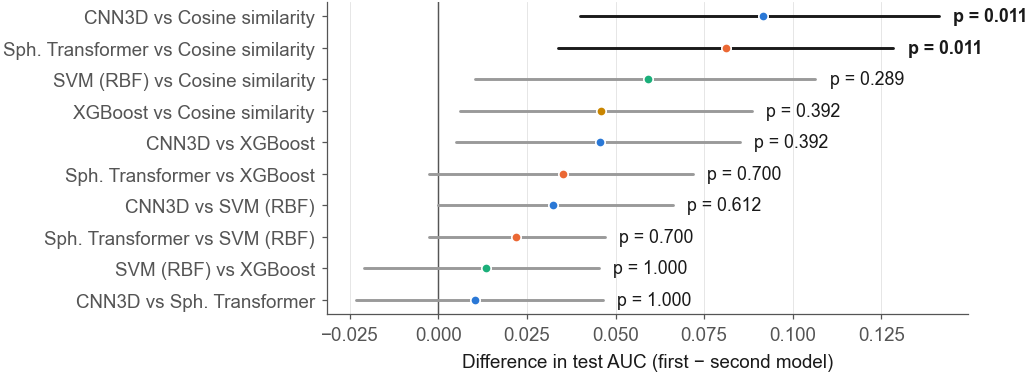

In [8]:
fig, ax = plt.subplots(figsize=(COL15, 0.22 * len(pw) + 0.5))
ys = np.arange(len(pw))[::-1]
ax.axvline(0, color=INK_2, lw=0.7)
for y, (_, r) in zip(ys, pw.iterrows()):
    strong = r["p_holm"] < 0.05
    ax.plot([r["lo"], r["hi"]], [y, y], color=INK if strong else "#9a9a9a", lw=1.4, solid_capstyle="round")
    ax.plot(r["delta_AUC"], y, "o", ms=4.5, color=color(r["config_a"]), mec="white", mew=0.8, zorder=5)
    ax.text(max(r["hi"], 0) + 0.004, y, pfmt(r["p_holm"]).replace("p = ", "p = "), va="center", fontsize=8.5,
            fontweight="bold" if strong else "normal")
ax.set_yticks(ys, [f"{SHORT[a]} vs {SHORT[b]}" for a, b in zip(pw["config_a"], pw["config_b"])])
ax.set_xlabel("Difference in test AUC (first − second model)")
ax.grid(axis="y", visible=False)
save(fig, "fig4_pairwise",
     "Pairwise differences in seed-mean test AUC between the primary configurations. Bars: unadjusted "
     "95% paired-bootstrap CI; dots coloured by the better model; labels: Holm-adjusted p-values "
     "(bold, black bars: p < 0.05).")
plt.show()

## 4. Operating points

**fig5_confusion** (190 × 43 mm): Test-set confusion matrices at each model's validation-chosen threshold (counts averaged over seeds where applicable; percentages are row-normalized, i.e. specificity and sensitivity on the diagonal).

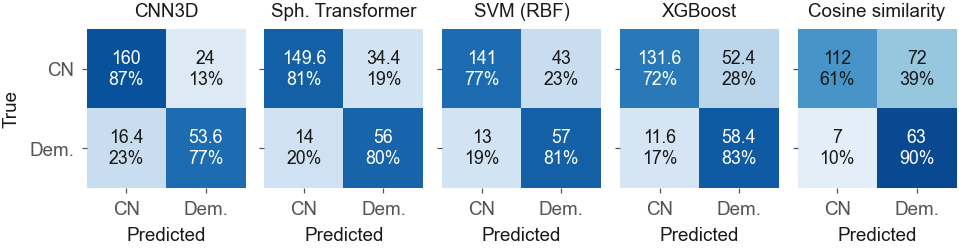

,Sensitivity,Specificity,PPV,NPV,F1 score
CNN3D,0.766 ± 0.105 (0.687–0.842),0.870 ± 0.039 (0.824–0.911),0.696 ± 0.045 (0.605–0.790),0.909 ± 0.035 (0.870–0.943),0.724 ± 0.037 (0.651–0.793)
Sph. Transformer,0.800 ± 0.058 (0.718–0.875),0.813 ± 0.028 (0.762–0.859),0.620 ± 0.035 (0.531–0.710),0.915 ± 0.022 (0.875–0.949),0.698 ± 0.037 (0.623–0.768)
SVM (RBF),0.814 (0.719–0.901),0.766 (0.705–0.826),0.570 (0.471–0.670),0.916 (0.869–0.957),0.671 (0.583–0.747)
XGBoost,0.834 ± 0.071 (0.761–0.902),0.715 ± 0.051 (0.658–0.773),0.530 ± 0.030 (0.440–0.619),0.921 ± 0.026 (0.880–0.956),0.646 ± 0.019 (0.570–0.716)
Cosine similarity,0.900 (0.826–0.966),0.609 (0.537–0.679),0.467 (0.384–0.557),0.941 (0.896–0.982),0.615 (0.534–0.696)


F1 (harmonic mean of PPV and sensitivity, at the validation-chosen threshold) is highest for **CNN3D: 0.724 (95% CI 0.651–0.793)**. F1 is lower than AUC for every model because the test partition is imbalanced (70 of 254 are Dementia), which caps PPV; it depends on the threshold, whereas AUC does not.

In [9]:
fig, axes = plt.subplots(1, len(primary), figsize=(COL2, COL2 / len(primary) * 1.12),
                         gridspec_kw={"wspace": 0.12})
for i, (ax, c) in enumerate(zip(axes, primary)):
    g = per_seed[per_seed["config"] == c]
    cm = np.array([[g["TN"].mean(), g["FP"].mean()], [g["FN"].mean(), g["TP"].mean()]])
    frac = cm / cm.sum(axis=1, keepdims=True)
    cmap = plt.get_cmap("Blues")
    ax.imshow(frac, cmap=cmap, vmin=0, vmax=1)
    for (r_, k), v in np.ndenumerate(cm):
        txt = f"{v:.0f}" if float(v).is_integer() else f"{v:.1f}"
        rr, gg, bb, _ = cmap(frac[r_, k])                   # pick ink by cell luminance
        ink = "white" if 0.2126 * rr + 0.7152 * gg + 0.0722 * bb < 0.45 else INK
        ax.text(k, r_, f"{txt}\n{frac[r_, k]:.0%}", ha="center", va="center", fontsize=8.5, color=ink)
    ax.set_xticks([0, 1], ["CN", "Dem."])
    ax.set_yticks([0, 1], ["CN", "Dem."] if i == 0 else ["", ""])
    ax.set_xlabel("Predicted")
    ax.set_title(SHORT[c], fontsize=9)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel("True")
save(fig, "fig5_confusion",
     "Test-set confusion matrices at each model's validation-chosen threshold (counts averaged over "
     "seeds where applicable; percentages are row-normalized, i.e. specificity and sensitivity on the diagonal).")
plt.show()

op = pd.DataFrame({NAMES[k]: [cell(summary.loc[c], k) for c in primary] for k in ["Sens", "Spec", "PPV", "NPV", "F1"]},
                  index=[SHORT[c] for c in primary])
display(op)
bf1 = summary.loc[primary, "F1_mean"].idxmax()
display(Markdown(
    f"F1 (harmonic mean of PPV and sensitivity, at the validation-chosen threshold) is highest for "
    f"**{SHORT[bf1]}: {ci(summary.loc[bf1], 'F1')}**. F1 is lower than AUC for every model because the test "
    f"partition is imbalanced ({meta['n_test_dementia']} of {meta['n_test']} are Dementia), which caps PPV; "
    "it depends on the threshold, whereas AUC does not."))

## 5. Acquisition protocol: stratified performance

**fig6_protocol_subgroups** (190 × 119 mm): Test AUC computed separately within each acquisition protocol: (a) scans with 1.2 mm left-right slices; (b) scans with ≤1.0 mm voxels. Bars: 95% bootstrap CI (resampling within the protocol). The voxel-spacing-only classifier falls to chance once protocol is held fixed.

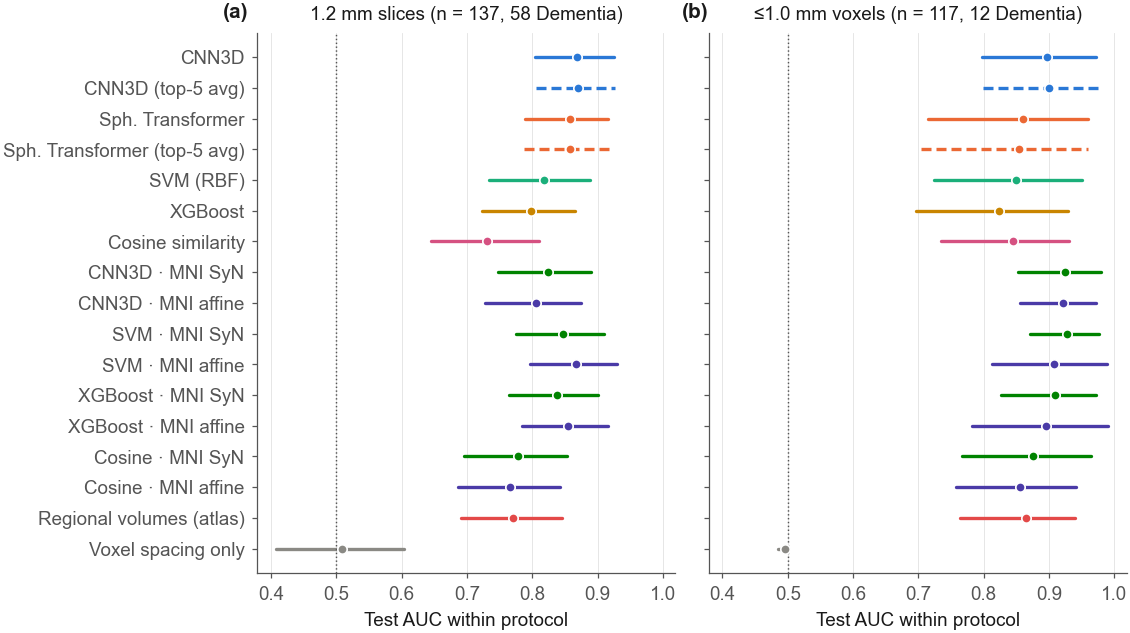

,Overall,≤1.0 mm voxels,1.2 mm slices
CNN3D,0.893,0.897,0.868
CNN3D (top-5 avg),0.896,0.899,0.871
Sph. Transformer,0.882,0.860,0.858
Sph. Transformer (top-5 avg),0.883,0.854,0.858
SVM (RBF),0.860,0.850,0.818
XGBoost,0.847,0.824,0.798
Cosine similarity,0.801,0.845,0.730
CNN3D · MNI SyN,0.893,0.924,0.824
CNN3D · MNI affine,0.882,0.921,0.805
SVM · MNI SyN,0.891,0.928,0.848


Within-protocol AUC of CNN3D: 0.868 (1.2 mm slices) and 0.897 (≤1.0 mm), against 0.893 overall, so the headline AUC is not driven by protocol. The spacing-only control drops from 0.702 overall to 0.508 / 0.495 within protocol. Note: the ≤1.0 mm test subgroup contains only 12 Dementia cases, so its intervals are wide.

In [10]:
protos = ["slice1.2", "iso1.0"]
fig, axes = plt.subplots(1, 2, figsize=(COL2, 0.24 * len(present) + 0.6), sharey=True, sharex=True,
                         gridspec_kw={"wspace": 0.08})
ys = np.arange(len(present))[::-1]
for i, (ax, proto) in enumerate(zip(axes, protos)):
    sg = subgroup[subgroup["protocol"] == proto].set_index("config")
    for y, c in zip(ys, present):
        r = sg.loc[c]
        ax.plot([r["AUC_lo"], r["AUC_hi"]], [y, y], color=color(c), lw=1.6, ls=lstyle(c), solid_capstyle="round")
        ax.plot(r["AUC_mean"], y, "o", ms=4.5, color=color(c), mec="white", mew=0.8, zorder=5)
    first = sg.iloc[0]
    ax.set_title(f"{PROTO[proto]} (n = {int(first['n'])}, {int(first['n_dementia'])} Dementia)")
    ax.axvline(0.5, color=INK_2, lw=0.7, ls=":")
    ax.set_xlabel("Test AUC within protocol")
    ax.grid(axis="y", visible=False)
    panel(ax, "ab"[i], x=0.0 if i else -0.02)
axes[0].set_yticks(ys, [SHORT[c] for c in present])
save(fig, "fig6_protocol_subgroups",
     "Test AUC computed separately within each acquisition protocol: (a) scans with 1.2 mm left-right "
     "slices; (b) scans with ≤1.0 mm voxels. Bars: 95% bootstrap CI (resampling within the protocol). "
     "The voxel-spacing-only classifier falls to chance once protocol is held fixed.")
plt.show()

sgp = subgroup.pivot(index="config", columns="protocol", values="AUC_mean").loc[present]
sgp.index = [SHORT[c] for c in present]
sgp.columns = [PROTO[p] for p in sgp.columns]
sgp.insert(0, "Overall", summary.loc[present, "AUC_mean"].values)
display(sgp.round(3))
n_iso = int(subgroup.loc[subgroup["protocol"] == "iso1.0", "n_dementia"].iloc[0])
c0 = primary[0]
display(Markdown(
    f"Within-protocol AUC of {SHORT[c0]}: {sgp.loc[SHORT[c0], PROTO['slice1.2']]:.3f} (1.2 mm slices) and "
    f"{sgp.loc[SHORT[c0], PROTO['iso1.0']]:.3f} (≤1.0 mm), against {sgp.loc[SHORT[c0], 'Overall']:.3f} overall, "
    "so the headline AUC is not driven by protocol. "
    + (f"The spacing-only control drops from {sgp.loc[SHORT[CONTROL], 'Overall']:.3f} overall to "
       f"{sgp.loc[SHORT[CONTROL], PROTO['slice1.2']]:.3f} / {sgp.loc[SHORT[CONTROL], PROTO['iso1.0']]:.3f} within protocol. "
       if CONTROL in summary.index else "")
    + f"Note: the ≤1.0 mm test subgroup contains only {n_iso} Dementia cases, so its intervals are wide."))

## 6. Acquisition protocol: cross-protocol generalization

**fig7_cross_protocol** (190 × 72 mm): Cross-protocol generalization, with the test subjects held fixed: test subjects with (a) 1.2 mm slices and (b) ≤1.0 mm voxels, scored by a model trained only on the same protocol (open) or only on the other protocol (filled). Thresholds were chosen on the training protocol's validation subjects. Bars: 95% bootstrap CI.

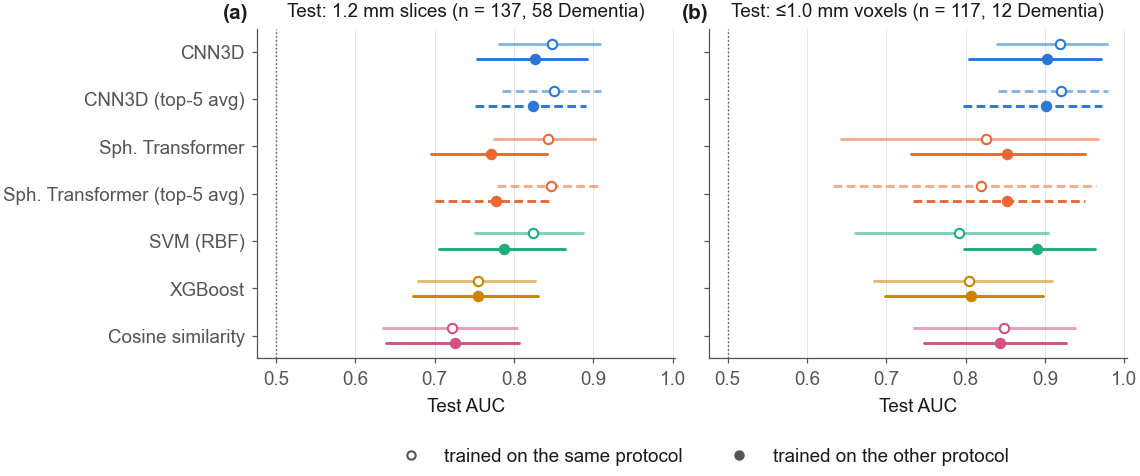

,Model,Test protocol,Trained on same,Trained on other,Change
0,CNN3D,1.2 mm slices,0.848,0.826,-0.022
1,CNN3D,≤1.0 mm voxels,0.919,0.902,-0.017
2,CNN3D (top-5 avg),1.2 mm slices,0.851,0.824,-0.027
3,CNN3D (top-5 avg),≤1.0 mm voxels,0.920,0.901,-0.019
4,Sph. Transformer,1.2 mm slices,0.843,0.771,-0.071
5,Sph. Transformer,≤1.0 mm voxels,0.826,0.852,0.026
6,Sph. Transformer (top-5 avg),1.2 mm slices,0.847,0.777,-0.070
7,Sph. Transformer (top-5 avg),≤1.0 mm voxels,0.820,0.852,0.033
8,SVM (RBF),1.2 mm slices,0.824,0.787,-0.037
9,SVM (RBF),≤1.0 mm voxels,0.791,0.890,0.099


Mean change in AUC when the model is trained on the *other* protocol: **-0.007** (range -0.071 to +0.099). A model that relied on protocol rather than disease would lose discrimination when transferred.

In [11]:
if cross is None:
    display(Markdown("`cross_protocol.csv` not found -- run `evaluate.py` without `--no-cross-protocol`."))
else:
    cfgs = [c for c in ORDER if c in set(cross["config"])]
    fig, axes = plt.subplots(1, 2, figsize=(COL2, 0.3 * len(cfgs) + 0.75), sharey=True, sharex=True,
                             gridspec_kw={"wspace": 0.08})
    ys = np.arange(len(cfgs))[::-1]
    for i, (ax, tp) in enumerate(zip(axes, protos)):
        same  = cross[(cross["eval_set"] == "in-protocol test") & (cross["test_protocol"] == tp)]
        other = cross[(cross["eval_set"] == "cross-protocol test") & (cross["test_protocol"] == tp)]
        for y, c in zip(ys, cfgs):
            for df, dy, filled in ((same, 0.16, False), (other, -0.16, True)):
                r = df[df["config"] == c]
                if r.empty:
                    continue
                r = r.iloc[0]
                ax.plot([r["AUC_lo"], r["AUC_hi"]], [y + dy, y + dy], color=color(c), lw=1.4,
                        ls=lstyle(c), solid_capstyle="round", alpha=1 if filled else 0.55)
                ax.plot(r["AUC_mean"], y + dy, "o", ms=4.5, mew=1, color=color(c),
                        mfc=color(c) if filled else "white", mec=color(c), zorder=5)
        ref = (same if not same.empty else other).iloc[0]
        ax.set_title(f"Test: {PROTO[tp]} (n = {int(ref['n'])}, {int(ref['n_dementia'])} Dementia)")
        ax.axvline(0.5, color=INK_2, lw=0.7, ls=":")
        ax.set_xlabel("Test AUC")
        ax.grid(axis="y", visible=False)
        panel(ax, "ab"[i], x=0.0 if i else -0.02)
    axes[0].set_yticks(ys, [SHORT[c] for c in cfgs])
    from matplotlib.lines import Line2D
    axes[1].legend(handles=[
        Line2D([], [], marker="o", ls="", mfc="white", mec=INK_2, color=INK_2, label="trained on the same protocol"),
        Line2D([], [], marker="o", ls="", mfc=INK_2, mec=INK_2, color=INK_2, label="trained on the other protocol")],
        loc="upper center", bbox_to_anchor=(-0.02, -0.22), ncol=2)
    save(fig, "fig7_cross_protocol",
         "Cross-protocol generalization, with the test subjects held fixed: test subjects with (a) 1.2 mm "
         "slices and (b) ≤1.0 mm voxels, scored by a model trained only on the same protocol (open) or only "
         "on the other protocol (filled). Thresholds were chosen on the training protocol's validation "
         "subjects. Bars: 95% bootstrap CI."
         + ("" if deep_cross else " Deep networks pending (protocol-restricted runs not yet trained)."))
    plt.show()

    rows = []
    for c in cfgs:
        for tp in protos:
            s_ = cross[(cross["config"] == c) & (cross["eval_set"] == "in-protocol test") & (cross["test_protocol"] == tp)]
            o_ = cross[(cross["config"] == c) & (cross["eval_set"] == "cross-protocol test") & (cross["test_protocol"] == tp)]
            if len(s_) and len(o_):
                rows.append({"Model": SHORT[c], "Test protocol": PROTO[tp],
                             "Trained on same": s_["AUC_mean"].iloc[0], "Trained on other": o_["AUC_mean"].iloc[0],
                             "Change": o_["AUC_mean"].iloc[0] - s_["AUC_mean"].iloc[0]})
    tx = pd.DataFrame(rows)
    display(tx.round(3))
    display(Markdown(
        f"Mean change in AUC when the model is trained on the *other* protocol: **{tx['Change'].mean():+.3f}** "
        f"(range {tx['Change'].min():+.3f} to {tx['Change'].max():+.3f}). A model that relied on protocol "
        "rather than disease would lose discrimination when transferred."))

## 6b. Registration-free vs. registration-based

The same subjects processed with conventional template registration (MNI152, ANTs affine and SyN):
the same CNN3D and PCA-based classifiers on the registered volumes, and a classic regional-volume
classifier (Harvard-Oxford subcortical atlas). Pre-specified pairs, ΔAUC = registration-free −
registration-based, paired bootstrap, Holm-adjusted within this family.

**fig8_registration** (190 × 74 mm): Registration-free versus registration-based processing of the same subjects. (a) Test AUC (mean across seeds, 95% bootstrap CI) of each registration-free configuration (upper) and its registration-based counterpart (lower; MNI152 2 mm, ANTs affine or SyN, or atlas regional volumes). (b) Paired difference in seed-mean AUC (registration-free minus registered), 95% paired-bootstrap CI and Holm-adjusted p-value within this pre-specified family (bold, black bars: p < 0.05).

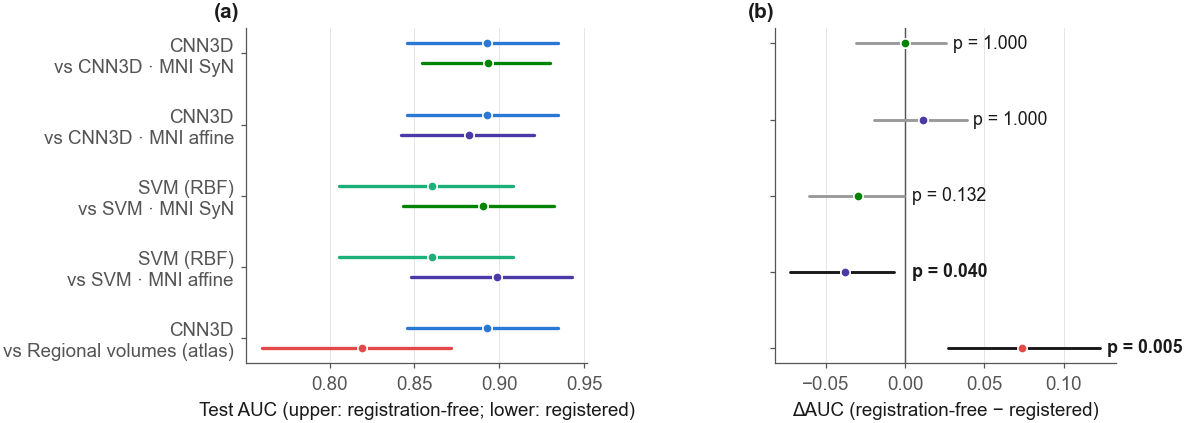

,Registration-free,Registered,AUC free,AUC registered,ΔAUC,95% CI,p (Holm)
0,CNN3D,CNN3D · MNI SyN,0.893,0.893,-0.000,-0.031 to +0.026,1.000
1,CNN3D,CNN3D · MNI affine,0.893,0.882,+0.011,-0.020 to +0.039,1.000
2,SVM (RBF),SVM · MNI SyN,0.860,0.891,-0.030,-0.061 to -0.001,0.132
3,SVM (RBF),SVM · MNI affine,0.860,0.899,-0.038,-0.073 to -0.007,0.040
4,CNN3D,Regional volumes (atlas),0.893,0.819,+0.074,+0.027 to +0.123,0.005


- **CNN3D vs CNN3D · MNI SyN:** ΔAUC -0.000 (95% CI -0.031 to +0.026, Holm p = 1.000): no significant difference.
- **CNN3D vs CNN3D · MNI affine:** ΔAUC +0.011 (95% CI -0.020 to +0.039, Holm p = 1.000): no significant difference.
- **SVM (RBF) vs SVM · MNI SyN:** ΔAUC -0.030 (95% CI -0.061 to -0.001, Holm p = 0.132): no significant difference.
- **SVM (RBF) vs SVM · MNI affine:** ΔAUC -0.038 (95% CI -0.073 to -0.007, Holm p = 0.040): registered better.
- **CNN3D vs Regional volumes (atlas):** ΔAUC +0.074 (95% CI +0.027 to +0.123, Holm p = 0.005): registration-free better.

In [12]:
reg_path = RESULTS_DIR / "registration_comparison.csv"
if not reg_path.exists():
    display(Markdown("`registration_comparison.csv` not found -- run `preprocessing/register.py`, "
                     "`run_experiments.ps1 -Registration` and `evaluate.py` first."))
else:
    rc = pd.read_csv(reg_path)
    fig, axes = plt.subplots(1, 2, figsize=(COL2, 0.42 * len(rc) + 0.8), gridspec_kw={"wspace": 0.55, "width_ratios": [1, 1]})
    ys = np.arange(len(rc))[::-1]
    ax = axes[0]
    for y, (_, r) in zip(ys, rc.iterrows()):
        for cfg, dy in ((r["config_a"], 0.14), (r["config_b"], -0.14)):
            s_ = summary.loc[cfg]
            ax.plot([s_["AUC_lo"], s_["AUC_hi"]], [y + dy, y + dy], color=color(cfg), lw=1.6, solid_capstyle="round")
            ax.plot(s_["AUC_mean"], y + dy, "o", ms=4.5, color=color(cfg), mec="white", mew=0.8, zorder=5)
    ax.set_yticks(ys, [f"{SHORT[a]}\nvs {SHORT[b]}" for a, b in zip(rc["config_a"], rc["config_b"])])
    ax.set_xlabel("Test AUC (upper: registration-free; lower: registered)")
    ax.grid(axis="y", visible=False)
    panel(ax, "a")
    ax = axes[1]
    ax.axvline(0, color=INK_2, lw=0.7)
    for y, (_, r) in zip(ys, rc.iterrows()):
        strong = r["p_holm"] < 0.05
        ax.plot([r["lo"], r["hi"]], [y, y], color=INK if strong else "#9a9a9a", lw=1.4, solid_capstyle="round")
        ax.plot(r["delta_AUC"], y, "o", ms=4.5, color=color(r["config_b"]), mec="white", mew=0.8, zorder=5)
        ax.text(max(r["hi"], 0) + 0.004, y, pfmt(r["p_holm"]), va="center", fontsize=8.5,
                fontweight="bold" if strong else "normal")
    ax.set_yticks(ys, ["" for _ in ys])
    ax.set_xlabel("ΔAUC (registration-free − registered)")
    ax.grid(axis="y", visible=False)
    panel(ax, "b", x=0.0)
    save(fig, "fig8_registration",
         "Registration-free versus registration-based processing of the same subjects. (a) Test AUC "
         "(mean across seeds, 95% bootstrap CI) of each registration-free configuration (upper) and its "
         "registration-based counterpart (lower; MNI152 2 mm, ANTs affine or SyN, or atlas regional volumes). "
         "(b) Paired difference in seed-mean AUC (registration-free minus registered), 95% paired-bootstrap "
         "CI and Holm-adjusted p-value within this pre-specified family (bold, black bars: p < 0.05).")
    plt.show()

    t4 = pd.DataFrame({
        "Registration-free": [SHORT[a] for a in rc["config_a"]],
        "Registered": [SHORT[b] for b in rc["config_b"]],
        "AUC free": [f"{summary.loc[a, 'AUC_mean']:.3f}" for a in rc["config_a"]],
        "AUC registered": [f"{summary.loc[b, 'AUC_mean']:.3f}" for b in rc["config_b"]],
        "ΔAUC": rc["delta_AUC"].map("{:+.3f}".format),
        "95% CI": [f"{l:+.3f} to {h:+.3f}" for l, h in zip(rc["lo"], rc["hi"])],
        "p (Holm)": rc["p_holm"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"),
    })
    display(t4)
    (FIG_DIR / "table4_registration.tex").write_text(
        t4.rename(columns={"ΔAUC": r"$\Delta$AUC", "95% CI": r"95\% CI"}).to_latex(index=False, escape=False)
          .replace("<0.001", "$<$0.001").replace("·", r"$\cdot$"), encoding="utf-8")

    def verdict(r):
        if r["p_holm"] >= 0.05:
            return "no significant difference"
        return "registration-free better" if r["delta_AUC"] > 0 else "registered better"
    display(Markdown("\n".join(
        f"- **{SHORT[r['config_a']]} vs {SHORT[r['config_b']]}:** ΔAUC {r['delta_AUC']:+.3f} "
        f"(95% CI {r['lo']:+.3f} to {r['hi']:+.3f}, Holm {pfmt(r['p_holm'])}): {verdict(r)}."
        for _, r in rc.iterrows())))

## 7. Training dynamics and checkpoint averaging (ablation)

**figS1_training_curves** (190 × 51 mm): Validation AUC per epoch for (a) CNN3D and (b) the Spherical Transformer, one line per seed; dots mark the epoch selected by early stopping (best validation AUC).

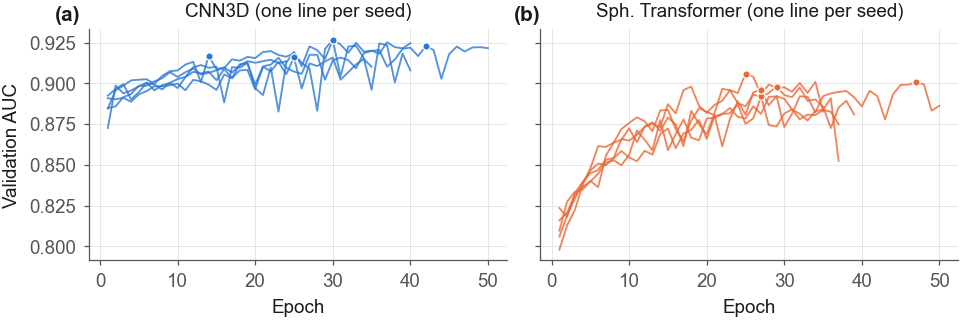

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.0), sharey=True, gridspec_kw={"wspace": 0.08})
for i, (ax, (d, fam)) in enumerate(zip(axes, [("CNN3D", "CNN3D"), ("Transformer", "Spherical Transformer")])):
    for run in sorted((RUNS_DIR / d).glob("seed*")):
        if not (run / "training.csv").exists():
            continue
        log = pd.read_csv(run / "training.csv")
        s = json.loads((run / "summary.json").read_text())
        ax.plot(log["epoch"], log["val_AUC"], color=FAMILY_COLOR[fam], lw=0.9, alpha=0.8)
        b = log.loc[log["epoch"] == s["best_epoch"], "val_AUC"]
        ax.plot(s["best_epoch"], b, "o", ms=3.5, color=FAMILY_COLOR[fam], mec="white", mew=0.6, zorder=5)
    ax.set_title(f"{SHORT[fam + ' (best epoch)']} (one line per seed)")
    ax.set_xlabel("Epoch")
    panel(ax, "ab"[i], x=0.0 if i else -0.02)
axes[0].set_ylabel("Validation AUC")
save(fig, "figS1_training_curves",
     "Validation AUC per epoch for (a) CNN3D and (b) the Spherical Transformer, one line per seed; "
     "dots mark the epoch selected by early stopping (best validation AUC).")
plt.show()

**figS2_ablation_averaging** (104 × 48 mm): Ablation: test AUC of best-epoch weights versus the element-wise average of the five epochs with the highest validation AUC, for (a) CNN3D and (b) the Spherical Transformer; one line per seed.

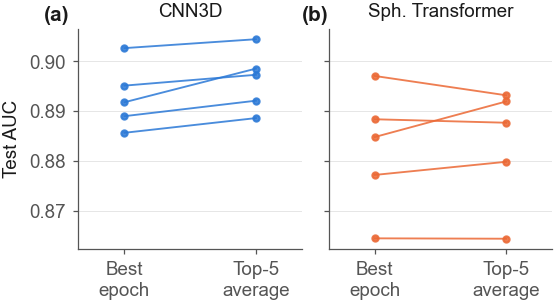

- CNN3D: ΔAUC (average − best) +0.003 (95% CI -0.000 to +0.007, Holm p = 0.700); sensitivity SD across seeds 0.105 → 0.051
- Sph. Transformer: ΔAUC (average − best) +0.001 (95% CI -0.003 to +0.005, Holm p = 1.000); sensitivity SD across seeds 0.058 → 0.038

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(COL1 * 1.15, 1.9), sharey=True, gridspec_kw={"wspace": 0.12})
abl = []
for i, (ax, fam) in enumerate(zip(axes, ["CNN3D", "Spherical Transformer"])):
    a = per_seed[per_seed["config"] == f"{fam} (best epoch)"].set_index("seed")["AUC"]
    b = per_seed[per_seed["config"] == f"{fam} (top-K avg)"].set_index("seed")["AUC"]
    for sd in a.index.intersection(b.index):
        ax.plot([0, 1], [a[sd], b[sd]], color=FAMILY_COLOR[fam], lw=0.9, marker="o", ms=3, alpha=0.85)
    ax.set_xticks([0, 1], ["Best\nepoch", "Top-5\naverage"])
    ax.set_xlim(-0.35, 1.35)
    ax.set_title(SHORT[fam + " (best epoch)"])
    ax.grid(axis="x", visible=False)
    panel(ax, "ab"[i], x=0.0 if i else -0.04)
    row = pairwise[(pairwise["config_a"] == f"{fam} (best epoch)") & (pairwise["config_b"] == f"{fam} (top-K avg)")]
    if len(row):
        r = row.iloc[0]
        abl.append(f"{SHORT[fam + ' (best epoch)']}: ΔAUC (average − best) {-r['delta_AUC']:+.3f} "
                   f"(95% CI {-r['hi']:+.3f} to {-r['lo']:+.3f}, Holm {pfmt(r['p_holm'])}); "
                   f"sensitivity SD across seeds {summary.loc[fam + ' (best epoch)', 'Sens_sd']:.3f} → "
                   f"{summary.loc[fam + ' (top-K avg)', 'Sens_sd']:.3f}")
axes[0].set_ylabel("Test AUC")
save(fig, "figS2_ablation_averaging",
     "Ablation: test AUC of best-epoch weights versus the element-wise average of the five epochs with the "
     "highest validation AUC, for (a) CNN3D and (b) the Spherical Transformer; one line per seed.")
plt.show()
display(Markdown("\n".join(f"- {s}" for s in abl)))

## 8. The spherical representation

In [ ]:
# same example subject as figures_spherical.py (Figs. 1 and 4); the PTID is kept in a local,
# gitignored file because ADNI subject identifiers are never published
subj_file = REPO / "cohort" / "figure_subjects.json"
example = json.loads(subj_file.read_text())["example"] if subj_file.exists() else None
path = CACHE_DIR / f"{example}.npy"
if example is None or not path.exists():
    display(Markdown("`spherical_cache/` not available on this machine -- Figure 1 skipped."))
else:
    T = np.load(path)                                   # (phi, theta, r) = (36, 72, 48)
    fracs = [0.25, 0.5, 0.75, 1.0]
    vmin, vmax = np.percentile(T, [1, 99])
    fig, axes = plt.subplots(1, len(fracs) + 1, figsize=(COL2, 1.45),
                             gridspec_kw={"width_ratios": [1] * len(fracs) + [0.04], "wspace": 0.2})
    for i, (ax, f) in enumerate(zip(axes, fracs)):
        k = int(round(f * T.shape[2])) - 1
        im = ax.imshow(T[:, :, k], origin="lower", cmap="gray", vmin=vmin, vmax=vmax,
                       extent=[0, 360, -90, 90], aspect="auto", interpolation="nearest")
        ax.set_title(f"r = {f:g} R$_{{edge}}$")
        ax.set_xticks([0, 90, 180, 270]); ax.set_xlabel("Azimuth θ (°)")
        ax.set_yticks([-90, -45, 0, 45, 90])
        ax.tick_params(labelleft=(i == 0))
        ax.grid(False)
        panel(ax, "abcd"[i], x=0.0 if i else -0.06)
    axes[0].set_ylabel("Elevation φ (°)")
    fig.colorbar(im, cax=axes[-1], label="Normalized intensity")
    save(fig, "fig1_spherical_tensor",
         "Spherical intensity tensor of one training subject, shown as elevation × azimuth maps at four "
         "fractional radii (a–d) of the subject's own per-direction brain boundary R$_{edge}$ "
         "(36 × 72 angular bins of 5°; 48 radial samples).")
    plt.show()

Output omitted from the repository: this figure shows one ADNI participant's spherical tensor (ADNI Data Use Agreement). Re-run the cell locally to view it.


## 9. Exported files and draft captions

In [16]:
order = ["fig1_spherical_tensor", "fig2_roc", "fig3_auc_forest", "fig4_pairwise", "fig5_confusion",
         "fig6_protocol_subgroups", "fig7_cross_protocol", "fig8_registration",
         "figS1_training_curves", "figS2_ablation_averaging"]
lines = ["# Draft figure captions", "",
         "Generated by notebooks/results.ipynb from results/ and runs/. Numbers update when the notebook is re-run.", ""]
for name in [n for n in order if n in CAPTIONS]:
    lines += [f"**{name}.** {CAPTIONS[name]}", ""]
(FIG_DIR / "captions.md").write_text("\n".join(lines), encoding="utf-8")

files = sorted(p.name for p in FIG_DIR.iterdir())
display(Markdown(f"Wrote {len(files)} files to `{FIG_DIR}`:\n\n" + ", ".join(f"`{f}`" for f in files)))

Wrote 81 files to `F:\adni-spherical-classification\figures`:

`backprojection.pdf`, `backprojection.png`, `backprojection.tif`, `captions.md`, `captions_registration.md`, `cn_vs_ad.pdf`, `cn_vs_ad.png`, `cn_vs_ad.tif`, `exploratory`, `fig10_registration_pairs.pdf`, `fig10_registration_pairs.png`, `fig10_registration_pairs.tif`, `fig11_registration_roc.pdf`, `fig11_registration_roc.png`, `fig11_registration_roc.tif`, `fig12_registration_protocol.pdf`, `fig12_registration_protocol.png`, `fig12_registration_protocol.tif`, `fig13_registration_spherical.pdf`, `fig13_registration_spherical.png`, `fig13_registration_spherical.tif`, `fig1_spherical_tensor.pdf`, `fig1_spherical_tensor.png`, `fig1_spherical_tensor.tif`, `fig2_roc.pdf`, `fig2_roc.png`, `fig2_roc.tif`, `fig3_auc_forest.pdf`, `fig3_auc_forest.png`, `fig3_auc_forest.tif`, `fig4_pairwise.pdf`, `fig4_pairwise.png`, `fig4_pairwise.tif`, `fig5_confusion.pdf`, `fig5_confusion.png`, `fig5_confusion.tif`, `fig6_protocol_subgroups.pdf`, `fig6_protocol_subgroups.png`, `fig6_protocol_subgroups.tif`, `fig7_cross_protocol.pdf`, `fig7_cross_protocol.png`, `fig7_cross_protocol.tif`, `fig8_registration.pdf`, `fig8_registration.png`, `fig8_registration.tif`, `fig9_registration_grid.pdf`, `fig9_registration_grid.png`, `fig9_registration_grid.tif`, `figS1_training_curves.pdf`, `figS1_training_curves.png`, `figS1_training_curves.tif`, `figS2_ablation_averaging.pdf`, `figS2_ablation_averaging.png`, `figS2_ablation_averaging.tif`, `figS4_registration_agreement.pdf`, `figS4_registration_agreement.png`, `figS4_registration_agreement.tif`, `figS_gradcam.pdf`, `figS_gradcam.png`, `figS_gradcam.tif`, `figS_gradcam_rays.pdf`, `figS_gradcam_rays.png`, `figS_gradcam_rays.tif`, `figS_gradcam_shells.html`, `figS_gradcam_shells.pdf`, `figS_gradcam_shells.png`, `figS_gradcam_shells.tif`, `group_effect_map.pdf`, `group_effect_map.png`, `group_effect_map.tif`, `rays_3d.pdf`, `rays_3d.png`, `rays_3d.tif`, `table1_cohort.tex`, `table2_results.csv`, `table2_results.tex`, `table3_pairwise.tex`, `table4_registration.tex`, `table5_registration_full.csv`, `table5_registration_grid.tex`, `table6_registration_spherical.tex`